# The MRI System

**Part:** B — Hardware · **Reading time:** ~50 min · **Pass 1 overview:** [The MRI Scanner](../pass1_big_picture/P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Magnetism from currents](../refreshers/RP1_Magnetism_from_Currents.ipynb), [Induction and RF](../refreshers/RP2_Induction_and_RF.ipynb), [Continuous FT and DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)

Every MRI system consists of several major components that are required to create a measurable magnetic resonance signal and to localize where in the body it came from. In this chapter we "cut open" a scanner and look at what is inside, *why* each part is there, and how big the numbers are (fields, frequencies, powers, voltages, costs). This is the **map** of the hardware part of the course: each subsystem is covered in depth in its own chapter ([B2 fields](B2_Magnetic_Fields_in_MRI.ipynb), [B3 main magnet](B3_Main_Magnet_Engineering.ipynb), [B4 gradients](B4_Gradient_System_Engineering.ipynb), [B5 RF chain](B5_RF_System_and_Receive_Chain.ipynb), [B6 safety](B6_MRI_Safety.ipynb)).

## Learning goals

1. Describe the fundamental hardware components of an MRI scanner and why they are necessary
    * What are the required components of an MRI system?
    * What is the purpose of each component, and in which step of the MRI experiment is it used?
    * What calibrations are required for an MRI scan (at installation and before every scan)?
    * Answer these questions:
        * Why is MRI so loud?
        * Why is it dangerous to bring certain metals into an MRI scanner?
2. *(new)* Know the supporting subsystems that a real scanner cannot work without: shim coils, spectrometer/sequencer, RF power amplifier, preamplifiers and ADCs, reconstruction computer, Faraday cage, patient table, cooling and cryogenics.
3. *(new)* Quote the order of magnitude of every field, frequency, power and signal level in the system.
4. *(new)* Explain the trade-offs between clinical field strengths (0.55 T, 1.5 T, 3 T, 7 T), open vs closed bores, and what drives the cost of a scanner.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x, y, z$ | position coordinates; $z$ along the bore (the $B_0$ direction) | m | |
| $\vec r = [x,y,z]^T$ | position vector | m | |
| $t$ | time | s | |
| $B_0$ | main static magnetic field (along $z$) | T | 0.55, 1.5, 3, 7 T |
| $\Delta B_0(\vec r)$ | deviation of the static field from $B_0$ | T | quoted in ppm of $B_0$ |
| ppm | "parts per million" = $10^{-6}$ (relative) | – | 1 ppm of 3 T = 3 µT |
| $B_1^+(\vec r,t)$ | transmit RF field (the rotating component that tips spins) | T | ~1–25 µT |
| $B_1^-(\vec r)$ | receive sensitivity of an RF coil (field per unit current) | T/A | ~µT/A |
| $\vec G(t)=[G_x,G_y,G_z]^T$ | gradient: rate of change of $B_z$ with position | T/m | 20–80 mT/m |
| $SR$ | slew rate = maximum $dG/dt$ | T/m/s | 100–200 T/m/s |
| $\gamma$ | gyromagnetic ratio (angular) | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio ("gamma-bar") | Hz/T | 42.58 MHz/T for ¹H |
| $f_0=\bar\gamma B_0$ | Larmor (resonance) frequency | Hz | 63.9 MHz @ 1.5 T, 127.7 MHz @ 3 T |
| $\Delta f$ | frequency offset from $f_0$ | Hz | |
| $\theta$ | flip angle | rad (or °) | 90° = $\pi/2$ |
| $T_{rf}$ | RF pulse duration | s | 0.1–10 ms |
| $\vec M$, $M_0$ | net magnetization; its equilibrium value | A/m (normalized $M_0=1$ in simulations) | ~0.01 A/m for water at 3 T |
| $s(t)$ | received signal | V | µV–mV at the coil |
| $\sigma_n$ | standard deviation of the noise | V (or a.u.) | |
| $SNR$ | signal-to-noise ratio | – | |
| $g_{rx}$ | receiver gain (amplification before the ADC) — not the parallel-imaging g-factor | – (or dB) | |
| $b$ | number of bits of the analog-to-digital converter (ADC) | – | 14–18 |
| $I_c$ | electric current (in a wire or coil) | A | gradient coils: several hundred A |
| $\ell$ | length of a wire segment | m | |
| $F$ | force | N | |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |
| $c$ | speed of light | m/s | $3.0\times10^8$ |
| $\lambda$ | wavelength of the RF field | m | 2.35 m in air at 127.7 MHz |
| $\varepsilon_r$ | relative permittivity of tissue | – | ~50–80 (water-rich tissue) |
| $f_c$, $d$ | cutoff frequency and diameter of a waveguide (Faraday-cage penetration) | Hz, m | |
| $FOV$ | field of view | m | 0.2–0.5 m |

> **⚠️ Common confusion:** **T** (upright) is the unit *tesla*; $T$ (italic, no subscript) is temperature; $T_1, T_2$ are relaxation time constants. $I$ is the spin quantum number in physics chapters — in this hardware chapter we write currents as $I_c$ to avoid the clash.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Components of an MRI scanner

If we cut open a typical (closed-bore, superconducting) MRI scanner, it looks like this:

![MRI scanner cutaway (source: National High Magnetic Field Laboratory, Magnet Academy, http://www.magnet.fsu.edu/education/tutorials/magnetacademy/mri/)](../images/MRI_system_diagram.png)

*Cutaway of a cylindrical scanner. From the outside in: the superconducting **magnet** (inside its cryostat), the **gradient coils**, the **RF (body) coil**, and the patient lying on the **patient table**. Only the inner ~60–70 cm diameter "bore" is available for the patient.*

The scanner has **three hardware components that are required for every MRI scan**:

1. **Main magnet** — creates $B_0$
2. **Radiofrequency (RF) coils** — a transmit RF coil, described by its field $B_1^+(\vec r,t)$, and a receive RF coil, described by its sensitivity $B_1^-(\vec r)$
3. **Magnetic field gradient coils** — create $\vec G(t)$

Around these three sit many **supporting subsystems** that turn a physics experiment into a clinical machine. The block diagram below shows all of them and how signals, power and coolant flow between them.

### 1.1 Block diagram of a complete scanner

The next cell draws a block diagram. Colors group the subsystems: **blue** = magnet & cryogenics, **orange** = gradients, **green** = RF transmit, **gold** = RF receive, **gray** = computers & control, **light cyan** = cooling. The dashed outline is the **Faraday cage** (RF-shielded magnet room); every cable that enters it passes through a filtered **penetration panel**.

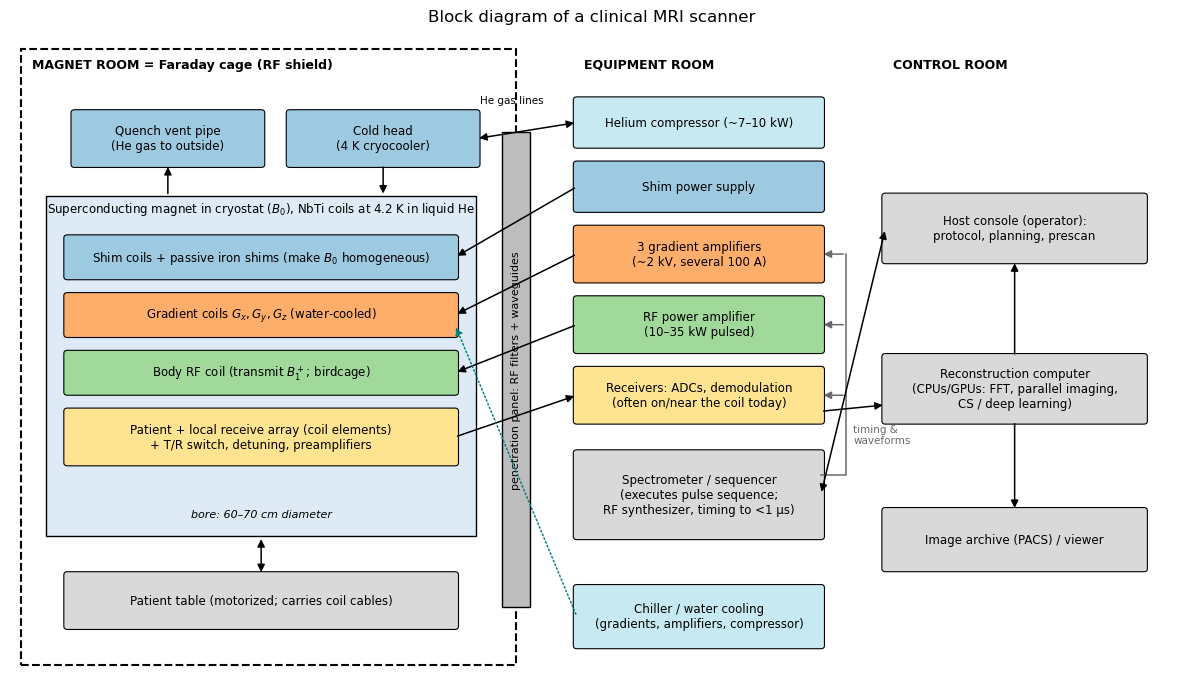

In [2]:
from matplotlib.patches import FancyBboxPatch

colors = {"magnet": "#9ecae1", "grad": "#fdae6b", "tx": "#a1d99b", "rx": "#fee391",
          "comp": "#d9d9d9", "cool": "#c7e9f1"}

def box(ax, x, y, w, h, text, kind, fs=8.5):
    """Draw a rounded box with centered text; return its anchor points."""
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc=colors[kind], ec="k", lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
    return {"l": (x, y + h / 2), "r": (x + w, y + h / 2), "t": (x + w / 2, y + h), "b": (x + w / 2, y)}

def arrow(ax, p, q, style="-|>", color="k", ls="-", both=False):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="<|-|>" if both else style, color=color,
                                                   lw=1.1, ls=ls, shrinkA=2, shrinkB=2))

fig, ax = plt.subplots(figsize=(15, 8.5))
ax.set_xlim(0, 16.2); ax.set_ylim(0, 10.2); ax.axis("off")

# --- magnet room (Faraday cage) ---
ax.add_patch(plt.Rectangle((0.15, 0.3), 6.9, 9.6, fill=False, ls="--", lw=1.5))
ax.text(0.3, 9.6, "MAGNET ROOM = Faraday cage (RF shield)", fontsize=9, weight="bold")
ax.add_patch(plt.Rectangle((0.5, 2.3), 6.0, 5.3, fc="#deebf7", ec="k", lw=1))
ax.text(3.5, 7.35, "Superconducting magnet in cryostat ($B_0$), NbTi coils at 4.2 K in liquid He", ha="center", fontsize=8.5)
shim = box(ax, 0.8, 6.35, 5.4, 0.6, "Shim coils + passive iron shims (make $B_0$ homogeneous)", "magnet")
grad = box(ax, 0.8, 5.45, 5.4, 0.6, "Gradient coils $G_x, G_y, G_z$ (water-cooled)", "grad")
body = box(ax, 0.8, 4.55, 5.4, 0.6, "Body RF coil (transmit $B_1^+$; birdcage)", "tx")
pat  = box(ax, 0.8, 3.45, 5.4, 0.8, "Patient + local receive array (coil elements)\n+ T/R switch, detuning, preamplifiers", "rx")
ax.text(3.5, 2.6, "bore: 60–70 cm diameter", ha="center", fontsize=8, style="italic")
table = box(ax, 0.8, 0.9, 5.4, 0.8, "Patient table (motorized; carries coil cables)", "comp")
vent = box(ax, 0.9, 8.1, 2.6, 0.8, "Quench vent pipe\n(He gas to outside)", "magnet")
cold = box(ax, 3.9, 8.1, 2.6, 0.8, "Cold head\n(4 K cryocooler)", "magnet")
arrow(ax, cold["b"], (5.2, 7.6)); arrow(ax, vent["b"], (2.2, 7.6), style="<|-")
arrow(ax, table["t"], (3.5, 2.3), style="<|-|>")

# --- penetration panel ---
ax.add_patch(plt.Rectangle((6.85, 1.2), 0.4, 7.4, fc="#bdbdbd", ec="k"))
ax.text(7.05, 4.9, "penetration panel: RF filters + waveguides", rotation=90, ha="center", va="center", fontsize=8)

# --- equipment room ---
ax.text(8.0, 9.6, "EQUIPMENT ROOM", fontsize=9, weight="bold")
comp = box(ax, 7.9, 8.4, 3.4, 0.7, "Helium compressor (~7–10 kW)", "cool")
shs  = box(ax, 7.9, 7.4, 3.4, 0.7, "Shim power supply", "magnet")
gpa  = box(ax, 7.9, 6.3, 3.4, 0.8, "3 gradient amplifiers\n(~2 kV, several 100 A)", "grad")
rfpa = box(ax, 7.9, 5.2, 3.4, 0.8, "RF power amplifier\n(10–35 kW pulsed)", "tx")
rcv  = box(ax, 7.9, 4.1, 3.4, 0.8, "Receivers: ADCs, demodulation\n(often on/near the coil today)", "rx")
spec = box(ax, 7.9, 2.3, 3.4, 1.3, "Spectrometer / sequencer\n(executes pulse sequence;\nRF synthesizer, timing to <1 µs)", "comp")
chil = box(ax, 7.9, 0.6, 3.4, 0.9, "Chiller / water cooling\n(gradients, amplifiers, compressor)", "cool")

# --- control room ---
ax.text(12.3, 9.6, "CONTROL ROOM", fontsize=9, weight="bold")
host = box(ax, 12.2, 6.6, 3.6, 1.0, "Host console (operator):\nprotocol, planning, prescan", "comp")
reco = box(ax, 12.2, 4.1, 3.6, 1.0, "Reconstruction computer\n(CPUs/GPUs: FFT, parallel imaging,\nCS / deep learning)", "comp")
pacs = box(ax, 12.2, 1.8, 3.6, 0.9, "Image archive (PACS) / viewer", "comp")

# --- connections (equipment -> magnet room via panel) ---
arrow(ax, comp["l"], cold["r"], both=True); ax.text(6.55, 9.05, "He gas lines", fontsize=7.5)
arrow(ax, shs["l"], shim["r"]); arrow(ax, gpa["l"], grad["r"]); arrow(ax, rfpa["l"], body["r"])
arrow(ax, pat["r"], rcv["l"])
# control "bus" from the sequencer to the amplifiers and receivers (right-hand side of the boxes)
xb = 11.65
ax.plot([spec["r"][0], xb, xb], [spec["r"][1] + 0.3, spec["r"][1] + 0.3, gpa["r"][1]], color="dimgray", lw=1.1)
for tgt in (gpa, rfpa, rcv):
    arrow(ax, (xb, tgt["r"][1]), tgt["r"], color="dimgray")
arrow(ax, host["l"], spec["r"], both=True)
arrow(ax, (rcv["r"][0], rcv["r"][1] - 0.25), (reco["l"][0], reco["l"][1] - 0.25)); arrow(ax, reco["t"], host["b"]); arrow(ax, reco["b"], pacs["t"])
arrow(ax, chil["l"], (6.2, 5.6), color="teal", ls=":")
ax.text(11.75, 3.75, "timing &\nwaveforms", fontsize=7.5, color="dimgray")
ax.set_title("Block diagram of a clinical MRI scanner", fontsize=12)
plt.show()

*Interpretation:* the magnet room contains only things that must be inside the field (magnet, coils, patient, preamplifiers); everything that is noisy, hot or ferromagnetic (amplifiers, compressors, computers) lives outside the RF shield and talks to the inside through filtered penetrations.

### 1.2 What each component does

| Component | Role in the MRI experiment | Typical numbers | Depth |
|---|---|---|---|
| **Main magnet** (superconducting solenoid in a cryostat) | **Polarization**: creates the strong, static, homogeneous $B_0$ that aligns spins and sets the Larmor frequency | 1.5–3 T clinical; homogeneity a few ppm over a 50 cm sphere; 1500 L liquid He (conventional) or < 10 L (sealed) | [B3](B3_Main_Magnet_Engineering.ipynb) |
| **Shim system** (passive iron pieces + shim coils) | Corrects $\Delta B_0(\vec r)$ from manufacturing, siting and the patient | 1st order (linear) via gradient offsets; 2nd–3rd order dedicated coils | [B3](B3_Main_Magnet_Engineering.ipynb) |
| **Gradient coils + gradient amplifiers** | **Spatial encoding**: add $\vec G\cdot\vec r$ to $B_z$; also slice selection, spoiling, diffusion weighting | 40–80 mT/m, 100–200 T/m/s; amplifiers ~2 kV, 600–900 A | [B4](B4_Gradient_System_Engineering.ipynb) |
| **RF transmit chain**: synthesizer → modulator → RF power amplifier → T/R switch → body coil | **Excitation**: create $B_1^+$ at $f_0$ to tip the magnetization | 10–35 kW peak; $B_1^+$ ≈ 1–25 µT; duty-cycle and SAR limited | [B5](B5_RF_System_and_Receive_Chain.ipynb) |
| **RF receive chain**: local coil array → preamplifiers → (demodulation) → ADC | **Acquisition**: pick up the tiny voltage induced by precessing $\vec M$ | 8–128 channels; preamp noise figure < 0.5 dB; signals µV–mV | [B5](B5_RF_System_and_Receive_Chain.ipynb) |
| **Spectrometer / sequencer** | Plays the **pulse sequence**: synchronizes RF, gradients and ADC on a common clock | timing resolution ≤ 1 µs (RF), ~10 µs gradient raster | [C1](C1_Pulse_Sequence.ipynb) |
| **Reconstruction computer** | Turns raw k-space data into images (FFT, parallel imaging, compressed sensing, deep learning) | multi-core CPUs + GPUs; raw data rates of 10s–100s of MB/s | [F3](F3_Image_Reconstruction.ipynb) |
| **Faraday cage** (RF-shielded room) | Keeps outside radio signals (FM radio, TV, aviation band!) from swamping the µV MR signal, and keeps the scanner's RF in | ≥ 90–100 dB attenuation from ~10 to ~130 MHz (higher for 7 T) | §2.6 below, [B5](B5_RF_System_and_Receive_Chain.ipynb) |
| **Patient table** | Positions the anatomy at the magnet isocenter (where the field is best) | positioning accuracy ~1 mm; carries coil connectors | |
| **Cooling & cryogenics** | Cold head + helium compressor keep the magnet at 4 K; chilled water removes the gradient and amplifier heat | compressor ~7–10 kW electric; gradients dissipate 10s of kW | [B3](B3_Main_Magnet_Engineering.ipynb), [B4](B4_Gradient_System_Engineering.ipynb) |
| **Safety systems** | Quench button, O₂ monitor, SAR/PNS monitoring, emergency stop | | [B6](B6_MRI_Safety.ipynb) |

## 2. The core components in more detail

### 2.1 Main magnet — $B_0$

The purpose of the main magnetic field is **polarization**: the preferential alignment of nuclear spins with a magnetic field. The more the spins are aligned, the larger the net magnetization $M_0$, and the larger the MRI signal. The stronger the field, the more alignment: $M_0 \propto B_0$ (derived in [Spin Physics](A1_Spin_Physics.ipynb)). In addition, $B_0$ sets the resonance (Larmor) frequency $f_0=\bar\gamma B_0$, and the induced signal voltage is proportional to that frequency too (Faraday's law, see [B2](B2_Magnetic_Fields_in_MRI.ipynb)) — which is why the raw signal grows roughly like $B_0^2$, and the SNR roughly like $B_0$ once body noise is included ([SNR](G2_Signal_to_Noise_Ratio.ipynb)).

Clinical fields are typically **1.5 T or 3 T** (≈ 30 000–60 000 × the Earth's field of ~50 µT). The field must be **homogeneous** — the same everywhere in the imaging volume to within a few parts per million (ppm). Reaching this field over a body-sized volume requires a **superconducting magnet**: coils of a superconducting alloy (niobium–titanium, NbTi) bathed in liquid helium at 4.2 K. Because the current circulates without resistance, this type of magnet is **always on**, even at night and during power failures.

Because of $B_0$ there is a large magnetic field inside *and around* the scanner (the "fringe field"), making it very **dangerous** to bring certain materials near the scanner. **Ferromagnetic** materials, such as iron, nickel, many steels, are strongly attracted (the "projectile effect") and twisted into alignment with the field.

> **🔧 Engineering reality:** a 3 T magnet stores ~10 MJ of magnetic energy (enough to lift a 1-tonne car 1 km), carries a persistent current of several hundred amperes, weighs 5–12 t, and costs on the order of a million dollars. Losing superconductivity (a **quench**) boils off most of the helium within a minute. All of this is the topic of [B3 Main Magnet Engineering](B3_Main_Magnet_Engineering.ipynb).

### 2.2 Radiofrequency (RF) coils — $B_1^+(\vec r,t)$, $B_1^-(\vec r)$

The purpose of the RF coils is **excitation** and **acquisition**. RF coils are resonant circuits (loops of conductor with capacitors) that create or pick up magnetic fields oscillating at radio frequencies. They must be **tuned** to the Larmor frequency of the system, because they only transmit and receive efficiently at their resonance frequency (see the [Induction and RF refresher](../refreshers/RP2_Induction_and_RF.ipynb)).

* **Excitation** means applying a magnetic field $B_1^+$ that rotates at the Larmor frequency. In the frame rotating with the spins, this field looks static, and the magnetization precesses about it, i.e. it is **tipped** away from the $z$-axis by the flip angle $\theta$. This is performed with a transmit RF coil. For MRI the frequency is in the radio-frequency range: 63.9 MHz at 1.5 T, 127.7 MHz at 3 T.
* **Acquisition**: after excitation, the transverse magnetization precesses at $f_0$. A precessing magnet is an oscillating magnetic field, and an oscillating field threading a loop of wire **induces a voltage** (Faraday's law). This voltage, $s(t)$, is the MR signal and is measured by the receive RF coil, characterized by its sensitivity $B_1^-(\vec r)$.

> **⚠️ Common confusion:** the original text says the spins "release energy" as they return to equilibrium and this energy is the signal. That picture is misleading: the signal is the **induced voltage of the precessing transverse magnetization** (a classical near-field induction effect, like a bicycle dynamo); relaxation actually makes the signal *disappear*. The energy exchanged is tiny and is not "radiated" in the antenna sense.

The RF coils are typically **separate transmit and receive coils** because the requirements differ: the transmit coil (usually the large **body coil** built into the bore) should create the *same* field — and therefore the same flip angle — everywhere in the field of view; the receive coils (small **local coil arrays** placed on the patient) should be as **sensitive** as possible to the tiny signals, which means small and close to the body.

> **🔧 Engineering reality:** the transmit amplifier delivers 10–35 kW pulses, while the receive chain must detect microvolts a few microseconds later, in the same room. This is why receive coils are actively **detuned** during transmission and why a **T/R switch** protects the preamplifiers. Details in [B5](B5_RF_System_and_Receive_Chain.ipynb).

### 2.3 Magnetic field gradient coils — $\vec G(t)$

The purpose of the gradient coils is **spatial encoding**, which enables the creation of images. These coils, usually simply called "**gradients**", create magnetic fields whose $z$-component varies **linearly** with position. These fields add to and subtract from the main field. Since the resonance frequency is proportional to the field strength ($f=\bar\gamma |\vec B|$), the frequency then varies with position, and signals from different locations can be separated ([Spatial Encoding](F1_Spatial_Encoding.ipynb)).

$$B_z(\vec r,t) = B_0 + \vec G(t)\cdot\vec r = B_0 + G_x(t)\,x + G_y(t)\,y + G_z(t)\,z$$

*In words:* the $z$-component of the field equals the main field plus a term that grows linearly along the direction of $\vec G$.
where $\vec G$ = gradient vector [T/m], $\vec r$ = position [m], $B_0$ = main field [T].

**Why MRI is so loud:** the noise is caused by rapidly switching currents in the gradient coils. A wire carrying current $I_c$ in a field $B_0$ feels the **Lorentz force**

$$F = I_c\,\ell\,B_0 \qquad (\text{wire perpendicular to } B_0)$$

*In words:* the force on a straight wire is current × length × field.
where $F$ = force [N], $I_c$ = current [A], $\ell$ = length of wire [m], $B_0$ = field [T].
When the current is switched on and off thousands of times per second, the coil is pushed back and forth like the membrane of a loudspeaker — and the "membrane" is a ~1 t coil assembly. Let's put in numbers.

In [3]:
# Lorentz force on gradient-coil conductors
I_c = 600.0      # gradient coil current [A] (modern amplifiers: 600-900 A)
ell = 1.0        # 1 m of conductor perpendicular to B0 [m]
for B0 in [0.55, 1.5, 3.0, 7.0]:
    F = I_c * ell * B0                     # [N]
    print(f"B0 = {B0:4.2f} T: force on 1 m of wire = {F:6.0f} N  (weight of {F/9.81:5.0f} kg)")

B0 = 0.55 T: force on 1 m of wire =    330 N  (weight of    34 kg)
B0 = 1.50 T: force on 1 m of wire =    900 N  (weight of    92 kg)
B0 = 3.00 T: force on 1 m of wire =   1800 N  (weight of   183 kg)
B0 = 7.00 T: force on 1 m of wire =   4200 N  (weight of   428 kg)


*Interpretation:* each metre of conductor is pushed with the weight of hundreds of kilograms, reversing at audio frequencies — so the gradient coil acts as a powerful loudspeaker (100–120 dB(A) at 3 T; ear protection is mandatory). The force scales with $B_0$, so higher-field scanners are louder. More in [B4](B4_Gradient_System_Engineering.ipynb) and [B6](B6_MRI_Safety.ipynb).

## 3. Supporting subsystems

### 3.1 Shim system
No magnet is perfect, and the patient's body itself distorts the field (tissue and air have different **magnetic susceptibilities**). **Shimming** is the process of adding small correction fields to make $B_0$ homogeneous again: **passive shims** (small pieces of steel placed in trays in the bore at installation) and **active shims** (coils whose currents are adjusted for each patient). First-order (linear) shims are simply DC offsets added to the three gradient coils; second- and higher-order shims are separate coils. → [B3](B3_Main_Magnet_Engineering.ipynb)

### 3.2 Spectrometer / sequencer
The "brain" that runs the **pulse sequence** ([Pulse Sequence](C1_Pulse_Sequence.ipynb)). It contains a frequency synthesizer at $f_0$ (plus offsets for slice selection), waveform generators for the RF envelope and the three gradient channels, and it triggers the ADC. Everything is derived from one stable reference clock, because the phase of the MR signal is meaningful: a timing jitter of 1 ns at 128 MHz is already a phase error of $360°\times 128\times10^6\times10^{-9}\approx 46°$.

### 3.3 RF transmit chain
Synthesizer → digital modulator (applies the pulse shape, e.g. a sinc) → **RF power amplifier** (solid-state, 10–35 kW peak at 1.5–3 T) → **T/R switch** → body coil. The power that can be used is limited by tissue heating (SAR, [B6](B6_MRI_Safety.ipynb)), by the amplifier's peak and average power, and by voltage breakdown in the coil. → [B5](B5_RF_System_and_Receive_Chain.ipynb)

### 3.4 RF receive chain
Coil element → **low-noise preamplifier** (the first amplifier dominates the noise, so it is placed directly at the coil) → filtering, amplification with adjustable **receiver gain** → **ADC** → digital demodulation to baseband (the "rotating frame" in software). Modern systems digitize directly in or near the coil and send data over optical fibre. A 64-channel coil sampled at 1 MHz complex bandwidth with 32-bit complex samples produces $64\times10^6\times 4\,\mathrm{B}\approx 256$ MB/s while the ADC is on. → [B5](B5_RF_System_and_Receive_Chain.ipynb)

### 3.5 Reconstruction computer
Receives the raw k-space data and computes images: FFT ([Image Reconstruction](F3_Image_Reconstruction.ipynb)), coil combination, parallel imaging and compressed sensing ([Accelerated Imaging](H3_Accelerated_Imaging_Methods.ipynb)), gradient non-linearity correction ("distortion correction"), and increasingly deep-learning reconstruction on GPUs.

### 3.6 Faraday cage (RF shielding)
The MR signal is a microvolt-level signal at 20–300 MHz — exactly the frequencies used by FM radio (88–108 MHz), TV, and at 3 T the **aviation band** (118–137 MHz contains 127.7 MHz!). The magnet room is therefore lined with copper (or galvanized steel) sheet, with RF-tight doors (spring "finger stock" around the door frame) and RF-shielded windows (a fine wire mesh). Any external RF that leaks in shows up as bright lines ("zipper" artifacts) in the image ([Artifacts](I2_Artifacts.ipynb)).

Cables entering the room go through **filters**; non-electrical connections (anaesthesia gas, fibres) go through **waveguides below cutoff**: metal tubes that do not let RF waves through if the tube is narrow compared to the wavelength. For a circular tube of diameter $d$ the lowest cutoff frequency is

$$f_c = \frac{1.841\,c}{\pi d}$$

*In words:* below $f_c$ a wave cannot propagate in the tube; it decays exponentially along it.
where $f_c$ = cutoff frequency [Hz], $c$ = speed of light [m/s], $d$ = inner diameter [m], 1.841 = first zero of the derivative of the Bessel function $J_1$ (geometry constant of the TE₁₁ mode).
For $f\ll f_c$ the field decays by a factor $e^{-2\pi f_c z/c}$ over a length $z$, i.e. by $20\log_{10}(e^{3.68}) \approx 32$ dB per tube *diameter* of length.

In [4]:
c = 2.998e8                       # speed of light [m/s]
for d in [0.01, 0.05, 0.10]:      # waveguide inner diameter [m]
    fc = 1.841 * c / (np.pi * d)                      # TE11 cutoff [Hz]
    att_per_m = 2 * np.pi * fc / c * np.sqrt(1 - (127.7e6 / fc) ** 2)   # attenuation [Np/m] at 127.7 MHz
    L_needed = 100 / (20 * np.log10(np.e) * att_per_m)                  # length for 100 dB [m]
    print(f"d = {d*100:4.0f} cm: f_c = {fc/1e9:5.2f} GHz, length for 100 dB at 127.7 MHz = {L_needed*100:5.1f} cm")

d =    1 cm: f_c = 17.57 GHz, length for 100 dB at 127.7 MHz =   3.1 cm
d =    5 cm: f_c =  3.51 GHz, length for 100 dB at 127.7 MHz =  15.6 cm
d =   10 cm: f_c =  1.76 GHz, length for 100 dB at 127.7 MHz =  31.4 cm


*Interpretation:* a 5 cm tube needs to be only ~16 cm long to block 100 dB of 127.7 MHz interference — which is why you see short metal tubes in the wall of every MRI room.

### 3.7 Patient table, cooling and cryogenics
* The **table** moves the anatomy of interest to the **isocenter**, the center of the magnet where $B_0$ is most homogeneous and the gradients are most linear. Coil plugs are integrated into the table.
* The **cold head** (a Gifford–McMahon or pulse-tube cryocooler) on top of the magnet re-condenses evaporating helium; its **helium compressor** (~7–10 kW electric) must run 24/7. If cooling stops, a conventional magnet slowly loses helium; see [B3](B3_Main_Magnet_Engineering.ipynb).
* A **chiller** supplies cooling water to the gradient coil (which dissipates up to tens of kW during demanding scans), the gradient and RF amplifiers and the compressor.
* A **quench vent pipe** leads helium gas safely out of the building if the magnet quenches ([B3](B3_Main_Magnet_Engineering.ipynb), [B6](B6_MRI_Safety.ipynb)).

## 4. Fundamental MRI experiment procedure

1. **Polarization:** place the subject in a large magnetic field
   * Components required: main magnet, $B_0$
2. **Excitation:** perturb the spins from equilibrium by applying an RF magnetic field at the Larmor frequency
   * Components required: transmit RF coil, $B_1^+(\vec r,t)$ (plus RF amplifier, sequencer)
3. **Acquisition:** detect the oscillating magnetic field of the precessing magnetization as an induced voltage
   * Components required: receive RF coil, $B_1^-(\vec r)$ (plus preamplifiers, ADC)
4. **Spatial encoding:** create spatial variations in the magnetic field to distinguish spins at different locations. This happens during excitation (slice selection) and acquisition (frequency/phase encoding).
   * Components required: magnetic field gradient coils, $\vec G(t)$ (plus gradient amplifiers)
5. **Repeat** excitation, acquisition and encoding as needed to acquire enough data to form an image (each repetition is one **TR**).

![Diagram of the MRI experiment: polarization, excitation, acquisition, spatial encoding](../images/MRI_experiment_diagram.png)

*The four steps of the MRI experiment. Polarization: spins partially align with $B_0$. Excitation: an RF field $B_1^+$ tips them. Acquisition: the precessing magnetization induces a signal in the receive coil ($B_1^-$). Spatial encoding: the gradient $\vec G\cdot\vec r$ makes the precession frequency depend on position.*

## 5. The numbers: fields, frequencies and signals

Every subsystem creates (or detects) a magnetic field, but with very different directions, magnitudes and time scales. This table (extended from [B2](B2_Magnetic_Fields_in_MRI.ipynb), where each field is derived) is worth memorizing:

| Field / quantity | Symbol | Direction | Time scale / frequency | Typical magnitude | Purpose |
|---|---|---|---|---|---|
| Earth's field (for comparison) | – | – | static | ~50 µT | – |
| Main field | $B_0$ | $z$ | static (DC, 0 Hz) | 0.55–7 T | polarization, sets $f_0$ |
| Main-field inhomogeneity | $\Delta B_0(\vec r)$ | $z$ | static | ~0.1–10 ppm (0.3–30 µT at 3 T) | unwanted (artifacts) |
| Gradient | $\vec G(t)$ | field along $z$, varying along $x,y,z$ | switched in ~0.1–1 ms, spectral content ~0.1–10 kHz | 10–80 mT/m → ~±10 mT at 25 cm from center | spatial encoding |
| Transmit RF | $B_1^+(\vec r,t)$ | $x$–$y$ plane (rotating) | $f_0$ ≈ 20–300 MHz, pulses 0.1–10 ms | 1–25 µT | excitation |
| Receive sensitivity | $B_1^-(\vec r)$ | $x$–$y$ plane | $f_0$ | ~µT per A | reception |
| Field of the magnetization itself | $\mu_0 \vec M$ | $x,y,z$ (precessing) | $f_0$ | ~10 nT for water at 3 T | signal source |
| Induced signal at the coil | $s(t)$ | – (a voltage) | $f_0$ | µV (one voxel: nV) up to ~mV (whole excited volume) | the data |

The next cell computes several of these from first principles so you can see where the numbers come from.

In [5]:
gb = mt.GAMMA_BAR                     # gamma-bar for 1H [Hz/T]
print("Larmor frequencies f0 = gamma_bar * B0 and RF wavelengths:")
eps_r = 60.0                          # rough relative permittivity of water-rich tissue (frequency dependent!)
for B0 in [0.064, 0.55, 1.5, 3.0, 7.0, 11.7]:
    f0 = mt.larmor_frequency(B0)
    lam_air = c / f0                  # wavelength in air [m]
    lam_tis = lam_air / np.sqrt(eps_r)  # approx. wavelength in tissue [m]
    tis = f"{lam_tis*100:5.1f} cm" if B0 >= 1.5 else "(eps_r model not valid at low f)"
    print(f"  B0 = {B0:6.3f} T: f0 = {f0/1e6:6.1f} MHz, lambda_air = {lam_air:6.2f} m, lambda_tissue ~ {tis}")

# Gradient: frequency spread across the field of view
G, FOV = 40e-3, 0.40                  # 40 mT/m, 40 cm FOV
print(f"\nGradient {G*1e3:.0f} mT/m over a {FOV*100:.0f} cm FOV: Bz varies by +-{G*FOV/2*1e3:.0f} mT "
      f"-> frequency spread +-{gb*G*FOV/2/1e3:.0f} kHz around f0")

# RF: B1 amplitude for a 90 degree rectangular pulse of 1 ms
B1 = mt.b1_for_flip(np.pi / 2, 1e-3)
print(f"B1 for a 90 deg, 1 ms hard pulse: {B1*1e6:.2f} uT  (= {B1/50e-6:.2f} x Earth's field)")

# Magnetization of water at 3 T and body temperature (derived in A1 Spin Physics)
N_H, T_body, B0 = 6.7e28, 310.0, 3.0
M0 = N_H * (mt.GAMMA * mt.HBAR) ** 2 * B0 / (4 * mt.K_BOLTZMANN * T_body)   # [A/m]
print(f"Water M0 at 3 T: {M0:.2e} A/m -> mu0*M0 = {mt.MU0*M0*1e9:.0f} nT")
print(f"Ratio B0 / (mu0*M0) = {B0/(mt.MU0*M0):.1e}: the signal source is ~300 million times weaker than B0")

Larmor frequencies f0 = gamma_bar * B0 and RF wavelengths:
  B0 =  0.064 T: f0 =    2.7 MHz, lambda_air = 110.02 m, lambda_tissue ~ (eps_r model not valid at low f)
  B0 =  0.550 T: f0 =   23.4 MHz, lambda_air =  12.80 m, lambda_tissue ~ (eps_r model not valid at low f)
  B0 =  1.500 T: f0 =   63.9 MHz, lambda_air =   4.69 m, lambda_tissue ~  60.6 cm
  B0 =  3.000 T: f0 =  127.7 MHz, lambda_air =   2.35 m, lambda_tissue ~  30.3 cm
  B0 =  7.000 T: f0 =  298.0 MHz, lambda_air =   1.01 m, lambda_tissue ~  13.0 cm
  B0 = 11.700 T: f0 =  498.2 MHz, lambda_air =   0.60 m, lambda_tissue ~   7.8 cm

Gradient 40 mT/m over a 40 cm FOV: Bz varies by +-8 mT -> frequency spread +-341 kHz around f0
B1 for a 90 deg, 1 ms hard pulse: 5.87 uT  (= 0.12 x Earth's field)
Water M0 at 3 T: 9.34e-03 A/m -> mu0*M0 = 12 nT
Ratio B0 / (mu0*M0) = 2.6e+08: the signal source is ~300 million times weaker than B0


*Interpretation:* the fields span **nine orders of magnitude** (T for $B_0$, mT for gradients, µT for $B_1$, nT for the magnetization), and the frequencies span DC, kHz and hundreds of MHz. At 3 T the RF wavelength in tissue (~30 cm) is already comparable to the body — the origin of $B_1^+$ inhomogeneity at high field ([B5](B5_RF_System_and_Receive_Chain.ipynb)).

The same story as a picture (log scale):

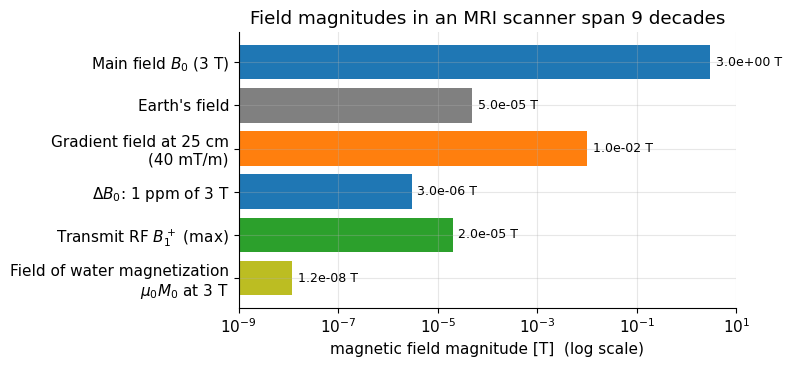

In [6]:
items = [("Main field $B_0$ (3 T)", 3.0, "C0"),
         ("Earth's field", 50e-6, "gray"),
         ("Gradient field at 25 cm\n(40 mT/m)", 40e-3 * 0.25, "C1"),
         ("$\\Delta B_0$: 1 ppm of 3 T", 3e-6, "C0"),
         ("Transmit RF $B_1^+$ (max)", 20e-6, "C2"),
         ("Field of water magnetization\n$\\mu_0 M_0$ at 3 T", mt.MU0 * M0, "C8")]
fig, ax = plt.subplots(figsize=(8, 3.8))
names = [n for n, _, _ in items][::-1]; vals = [v for _, v, _ in items][::-1]; cols = [c_ for _, _, c_ in items][::-1]
ax.barh(names, vals, color=cols)
ax.set_xscale("log"); ax.set_xlim(1e-9, 10)
ax.set_xlabel("magnetic field magnitude [T]  (log scale)")
for i, v in enumerate(vals):
    ax.text(v * 1.3, i, f"{v:.1e} T", va="center", fontsize=9)
ax.set_title("Field magnitudes in an MRI scanner span 9 decades")
plt.tight_layout(); plt.show()

*Interpretation:* the quantity we want to measure (bottom bar) is hundreds of millions of times smaller than the field we apply. MRI works anyway because the signal is at a precisely known frequency ($f_0$) and we can average coherently.

## 6. Calibrations

Calibrations of the individual components are performed both when the system is **installed** and before **every scan**.

### 6.1 Installation calibrations

1. **Main magnet:** small adjustments of the main field, called **shimming**, make $B_0$ more homogeneous (passive iron shims, superconducting shims; [B3](B3_Main_Magnet_Engineering.ipynb)).
2. **RF systems:** checking for sources of RF interference entering the scanner room (Faraday cage test), calibrating amplifier linearity and coil tuning.
3. **Gradient coils:** calibrating the gradient strength (so that 1 cm in the image is 1 cm in the patient), mapping the gradient **non-linearity** for distortion correction, and measuring/compensating **eddy currents** ("pre-emphasis"; [B4](B4_Gradient_System_Engineering.ipynb)).

### 6.2 Pre-scan calibrations ("prescan")

Different people, and different body regions, change both the main field (through **magnetic susceptibility**) and the RF fields (through electrical **loading** of the coils). Therefore calibrations are repeated for each patient (often for each series). This is called **prescan** and takes a few seconds:

1. **Shimming** (active): measure a $B_0$ field map in the region of interest, then set the shim currents to flatten it ([B3](B3_Main_Magnet_Engineering.ipynb) simulates this).
2. **Center frequency:** measure the resonance frequency of water in the region and set the synthesizer to it.
3. **Transmit gain** (RF power calibration): find the amplifier setting that gives a 90° (or 180°) flip angle. Often $B_1^+$ maps are also measured.
4. **Receiver gain:** set the amplification before the ADC so that the strongest signal uses most of the ADC range without clipping.
5. Often also: **coil sensitivity maps** $B_1^-$ for intensity correction and parallel imaging ([Accelerated Imaging](H3_Accelerated_Imaging_Methods.ipynb)), and noise calibration.

The following three small simulations show what steps 2–4 do.

#### Center frequency
The scanner excites a large region without gradients and records the free induction decay (FID). Its spectrum (via the FFT; see the [FT refresher](../refreshers/RM3_Continuous_FT_and_DFT.ipynb)) shows a water peak and, 3.5 ppm lower, a fat peak. The magnet may have drifted slightly, so the water peak is not exactly at 0 Hz. The scanner finds the water peak and shifts its synthesizer by that amount.

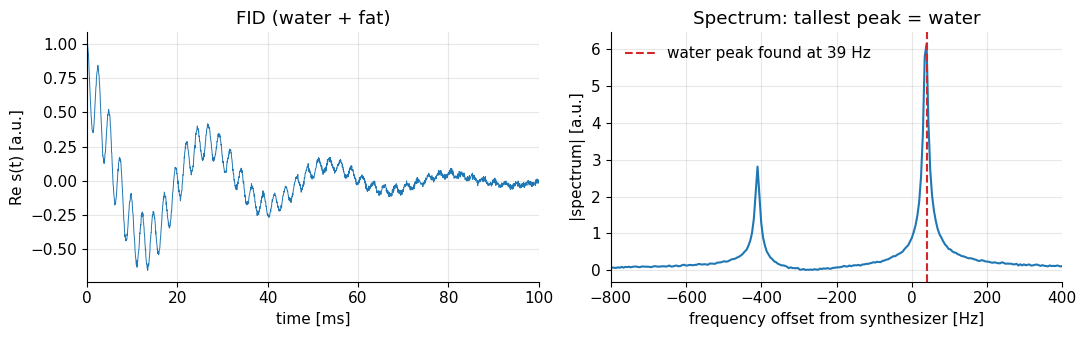

Set the new center frequency to f0 + 39.1 Hz (true offset 37.0 Hz; resolution 4.9 Hz)


In [7]:
B0 = 3.0
f_drift = 37.0                                  # true water offset from the synthesizer frequency [Hz]
f_fat = f_drift + mt.ppm_to_hz(mt.FAT_SHIFT_PPM, B0)  # fat is 3.5 ppm lower (~ -447 Hz at 3 T)
dt, N = 50e-6, 4096                             # dwell time [s] and number of samples -> BW = 20 kHz
t = np.arange(N) * dt
T2s = 0.03                                      # effective T2* [s]
# demodulated FID (rotating frame, left-handed convention exp(-i 2 pi f t)); water 70 %, fat 30 %
fid = (0.7 * np.exp(-1j * 2 * np.pi * f_drift * t) + 0.3 * np.exp(-1j * 2 * np.pi * f_fat * t)) * np.exp(-t / T2s)
fid = mt.add_complex_noise(fid, 0.01)
# With the exp(-i 2 pi f t) convention, a positive frequency appears at negative FFT frequency,
# so we use the inverse FFT to get a spectrum with positive offsets on the right.
spec = mt.ifftc(fid)
freqs = (np.arange(N) - N // 2) / (N * dt)      # frequency axis [Hz]
f_peak = freqs[np.argmax(np.abs(spec))]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t * 1e3, fid.real, lw=0.7); ax[0].set_xlim(0, 100)
ax[0].set_xlabel("time [ms]"); ax[0].set_ylabel("Re s(t) [a.u.]"); ax[0].set_title("FID (water + fat)")
ax[1].plot(freqs, np.abs(spec)); ax[1].set_xlim(-800, 400)
ax[1].axvline(f_peak, color="C3", ls="--", label=f"water peak found at {f_peak:.0f} Hz")
ax[1].set_xlabel("frequency offset from synthesizer [Hz]"); ax[1].set_ylabel("|spectrum| [a.u.]")
ax[1].set_title("Spectrum: tallest peak = water"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Set the new center frequency to f0 + {f_peak:.1f} Hz (true offset {f_drift} Hz; resolution {1/(N*dt):.1f} Hz)")

*Interpretation:* the scanner corrects the synthesizer by the measured offset. If it picked the fat peak by mistake (it happens in fatty regions, e.g. the breast), every image would be shifted and fat suppression would suppress water instead.

#### Transmit gain (flip-angle calibration)
The flip angle is $\theta = \gamma B_1 T_{rf}$ for a rectangular pulse, and $B_1$ is proportional to the amplifier voltage. But the proportionality constant depends on the patient (coil loading), so it is measured: the scanner sweeps the RF amplitude and watches the signal, which behaves like $|\sin\theta|$. Because $B_1^+$ is not perfectly uniform, the signal is an average over a spread of flip angles. Finding the **null at 180°** is more precise than finding the broad maximum at 90°.

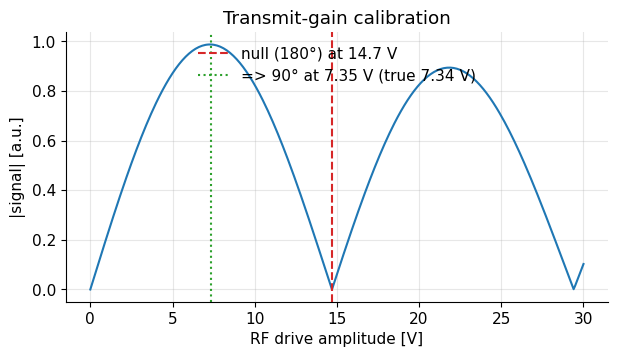

In [8]:
T_rf = 1e-3                                       # pulse length [s]
eff_true = 0.8e-6                                 # coil efficiency for this patient [T per volt of drive] (unknown to scanner)
V = np.linspace(0, 30, 301)                       # RF drive amplitude [V] (after scaling)
rng = np.random.default_rng(1)
b1_scale = 1 + 0.10 * rng.standard_normal(2000)   # +-10 % B1+ spread over the excited volume
theta = mt.GAMMA * (eff_true * V[:, None] * b1_scale[None, :]) * T_rf   # flip angle [rad], shape (V, spins)
signal = np.abs(np.mean(np.sin(theta), axis=1))    # magnitude of the averaged transverse magnetization

V90_true = np.pi / 2 / (mt.GAMMA * eff_true * T_rf)
i_max = np.argmax(signal)                         # first (broad) maximum ~ 90 degrees
i_null = i_max + np.argmax(np.diff(signal[i_max:]) > 0)   # first minimum after it ~ 180 degrees
V90_est = V[i_null] / 2                           # 180-degree null -> half amplitude gives 90 degrees
plt.figure(figsize=(7, 3.5))
plt.plot(V, signal)
plt.axvline(V[i_null], color="C3", ls="--", label=f"null (180°) at {V[i_null]:.1f} V")
plt.axvline(V90_est, color="C2", ls=":", label=f"=> 90° at {V90_est:.2f} V (true {V90_true:.2f} V)")
plt.xlabel("RF drive amplitude [V]"); plt.ylabel("|signal| [a.u.]"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0)); plt.title("Transmit-gain calibration")
plt.show()

*Interpretation:* the signal maximum (90°) is broad and flat, but the 180° null is sharp, so the scanner locates the null and halves the amplitude. All flip angles in the protocol are then scaled from this reference.

#### Receiver gain
The ADC has a fixed input range and a finite number of bits $b$. If the gain is too low, the signal occupies only a few ADC levels and **quantization noise** is added; if it is too high, the peak of the echo is **clipped**, which corrupts k-space (in images: ringing and artifacts). The scanner measures the echo peak and sets $g_{rx}$ so the peak uses a large fraction of the ADC range. Here we use a coarse 10-bit ADC to make the effect visible (real ADCs have 14–18 bits plus oversampling, which makes the low-gain side much more forgiving).

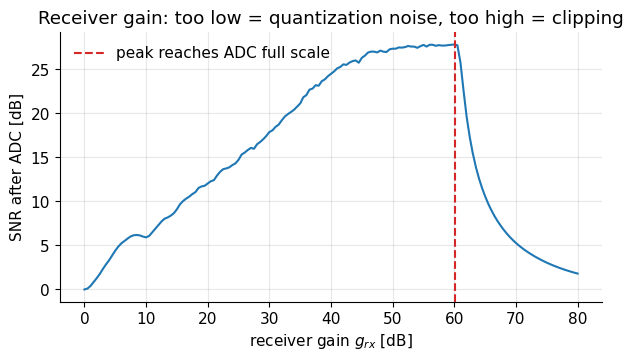

In [9]:
def adc(x, bits=10, full_scale=1.0):
    """Ideal ADC: clip to +-full_scale and round to 2**bits levels (applied to real and imaginary parts)."""
    step = 2 * full_scale / 2 ** bits
    q = lambda v: np.clip(np.round(v / step) * step, -full_scale, full_scale - step)
    return q(x.real) + 1j * q(x.imag)

rng = np.random.default_rng(0)
n = np.arange(-128, 128)
echo = 1e-3 * np.sinc(n / 8.0) * np.exp(1j * 0.3)        # echo at the coil, peak 1 mV (a.u. volts)
sigma_thermal = 5e-6                                     # thermal noise at the coil, 5 uV
x = mt.add_complex_noise(echo, sigma_thermal, rng)
gains_dB = np.linspace(0, 80, 161)
snr = []
for gdb in gains_dB:
    g = 10 ** (gdb / 20)                                 # voltage gain
    y = adc(g * x) / g                                   # digitize and refer back to the coil
    err = y - echo
    snr.append(np.linalg.norm(echo) / np.linalg.norm(err))
snr = np.array(snr)
g_clip = 20 * np.log10(1.0 / np.abs(x).max())             # gain at which the peak reaches full scale
plt.figure(figsize=(7, 3.5))
plt.plot(gains_dB, 20 * np.log10(snr))
plt.axvline(g_clip, color="C3", ls="--", label="peak reaches ADC full scale")
plt.xlabel("receiver gain $g_{rx}$ [dB]"); plt.ylabel("SNR after ADC [dB]")
plt.title("Receiver gain: too low = quantization noise, too high = clipping"); plt.legend()
plt.show()

*Interpretation:* SNR rises with gain until the thermal noise (not the ADC steps) dominates, stays flat, then collapses as soon as the echo peak clips. The scanner therefore sets the gain a few dB below the clipping point.

## 7. Field strengths in clinical use and their trade-offs

| $B_0$ | $f_0$ | Typical systems / uses | Advantages | Disadvantages |
|---|---|---|---|---|
| 0.064 T | 2.7 MHz | portable, permanent-magnet bedside scanners (e.g. Hyperfine Swoop) for ICU brain imaging | cheap, mobile, no cryogens, little shielding needed, very low SAR | very low SNR, long scans, limited resolution |
| 0.2–0.4 T | 8.5–17 MHz | open permanent or resistive magnets, MSK, claustrophobic patients | open access, cheaper, fewer safety issues | low SNR |
| **0.55 T** | 23.4 MHz | "low-field revival": modern high-performance gradients + advanced reconstruction (e.g. Siemens MAGNETOM Free.Max, 80 cm bore, < 1 L helium) | lower cost, less helium, fewer implant/heating issues, less susceptibility artifact (lungs, near metal), wider bore | ~1/3 the SNR of 1.5 T; slower or lower resolution |
| **1.5 T** | 63.9 MHz | clinical workhorse (body, cardiac, general) | mature, robust, good fat suppression, moderate SAR | half the SNR of 3 T |
| **3 T** | 127.7 MHz | neuro, MSK, prostate, research | ~2× SNR of 1.5 T, better spectroscopy & fMRI, faster | 4× SAR, more $B_1^+$ inhomogeneity (body), more susceptibility & chemical-shift artifacts, louder, more implant restrictions |
| **7 T** | 298 MHz | clinically approved for head and extremities since 2017 (e.g. Siemens MAGNETOM Terra); research | high SNR, resolution, susceptibility contrast, spectroscopy, X-nuclei | strong $B_1^+$ inhomogeneity (wavelength ~12 cm in tissue), SAR, vertigo, cost, many implants contraindicated |
| 10.5–11.7 T | 450–500 MHz | research (e.g. Minnesota 10.5 T, CEA Iseult 11.7 T) | ultimate SNR | extreme engineering (Iseult stores ~340 MJ) |

How these trade-offs follow from physics (SNR ∝ ~$B_0$, chemical shift and susceptibility ∝ $B_0$, SAR ∝ $B_0^2$, $T_1$ lengthening) is worked out with numbers in [B3, section "Field strength trade-offs"](B3_Main_Magnet_Engineering.ipynb).

> **🔧 Engineering reality:** the clinical "sweet spot" is set as much by engineering and economics as by physics: 1.5 T and 3 T magnets have mature, reliable designs, the RF wavelength is still manageable, and the implant-safety ecosystem (labels like "MR conditional at 1.5 T and 3 T") is built around them.

## 8. Open vs closed bore, and what drives cost

**Closed (cylindrical) bore** — a solenoid with horizontal $B_0$ along the patient. This is the most efficient way to make a strong, homogeneous field. Bore diameters: 60 cm (classic), 70 cm ("wide bore", now common at 1.5 and 3 T), 80 cm at 0.55 T. A wider bore helps claustrophobic and large patients, but it is harder and more expensive: the magnet must be larger for the same field and homogeneity, and the gradient coil efficiency drops steeply with radius (roughly ∝ 1/radius⁵ for the stored energy at fixed gradient strength, see [B4](B4_Gradient_System_Engineering.ipynb)).

**Open magnets** — two poles above and below the patient ("C-arm" or "H" shape), $B_0$ **vertical** (perpendicular to the patient). Permanent magnets (≤ 0.4 T) or superconducting pole designs (up to ~1–1.2 T). Excellent patient access (interventions, children, claustrophobia), but lower field and homogeneous volume. A nice side effect of a vertical $B_0$: solenoid-shaped receive coils wrapped around the body become possible (a solenoid's axis must be perpendicular to $B_0$, see [B2](B2_Magnetic_Fields_in_MRI.ipynb)), and solenoids are more sensitive than surface loops of similar size.

**Cost drivers** (orders of magnitude; prices vary widely by market):

| Item | Rough scale |
|---|---|
| Scanner purchase | often quoted as "roughly 1 M USD per tesla" for 1.5–3 T; 7 T several M USD |
| Magnet | the largest single cost: superconducting wire (tens of km of NbTi), cryostat, helium |
| Gradient and RF amplifiers | high-power electronics (several 100 kW peak gradient power) |
| Receive coils | each dedicated array coil costs tens of thousands USD |
| Siting | RF cage, magnetic shielding, floor reinforcement (magnet 4–12 t), quench pipe, chilled water, power: often several 100 k USD |
| Running costs | service contract (often ~10 % of the purchase price per year), electricity (tens of kW idle-to-scanning), helium refills for older magnets |

Helium price volatility and supply shortages are a major reason for the industry trend to **sealed, low-helium** magnets and to revisit lower fields ([B3](B3_Main_Magnet_Engineering.ipynb)).

## 9. Answers to the motivating questions

* **Why is MRI so loud?** Gradient coils carry hundreds of amperes inside a tesla-scale field. The Lorentz force ($F=I_c\ell B_0$, hundreds of kg-weight per metre of wire) reverses every time the gradient switches, so the coil vibrates like a loudspeaker at kHz frequencies. Louder at higher $B_0$ and for fast sequences (EPI, diffusion). → [B4](B4_Gradient_System_Engineering.ipynb)
* **Why is it dangerous to bring metal into the scanner?** Ferromagnetic objects are magnetized by the field and pulled towards the region where the field changes fastest (the bore entrance); the force grows with $B\,\nabla B$ and easily exceeds the object's weight by a factor of 10–100. They also experience a torque that aligns them with $B_0$. Conductive (even non-magnetic) implants can heat up due to the RF field. → [B3](B3_Main_Magnet_Engineering.ipynb), [B6](B6_MRI_Safety.ipynb)

## Key takeaways

* Three components are essential: **magnet** ($B_0$, polarization), **RF coils** ($B_1^+$ excitation, $B_1^-$ reception) and **gradient coils** ($\vec G$, spatial encoding).
* A real scanner adds shims, a sequencer/spectrometer, RF and gradient amplifiers, low-noise receivers and ADCs, a reconstruction computer, a Faraday cage, a table, cryogenics and water cooling.
* The fields span nine decades: T ($B_0$), mT (gradients), µT ($B_1$, ppm inhomogeneities), nT (the magnetization), and the signal is µV–mV at tens to hundreds of MHz.
* Prescan calibrates every patient: shim, center frequency, transmit gain (flip-angle reference), receiver gain.
* The signal is the voltage **induced** by precessing magnetization (Faraday), not "energy released by relaxation".
* Field-strength choice trades SNR against SAR, artifacts, $B_1$ inhomogeneity, safety and cost; 1.5 T and 3 T dominate clinically, with a revival of 0.55 T and growth of 7 T.
* MRI is loud because of Lorentz forces on switched gradient currents; ferromagnetic objects are dangerous because of forces ∝ $B\,\nabla B$.

## Check your understanding

1. Which component is used in each of the four steps of the MRI experiment (polarization, excitation, acquisition, encoding)?

<details><summary>Answer</summary>

Polarization: main magnet ($B_0$). Excitation: transmit RF coil + RF power amplifier ($B_1^+$). Acquisition: receive coil array + preamplifiers + ADC ($B_1^-$). Spatial encoding: gradient coils + gradient amplifiers ($\vec G$). The sequencer coordinates all of them, and the reconstruction computer turns the data into an image.

</details>

2. A 1.5 T scanner has drifted so that water is at +20 Hz relative to the synthesizer. Roughly what fraction of a ppm is this, and why should the scanner still correct it?

<details><summary>Answer</summary>

1 ppm at 1.5 T is 63.9 Hz, so 20 Hz ≈ 0.3 ppm. Uncorrected, it shifts the image in the readout direction by 20 Hz / (pixel bandwidth), shifts slices, makes spectral fat suppression less effective (the fat-suppression pulse is placed relative to the assumed water frequency), and causes banding shifts in bSSFP.

</details>

3. Why is the 180° null used for transmit calibration rather than the 90° maximum?

<details><summary>Answer</summary>

Near 90° the signal ∝ $\sin\theta$ is flat (derivative zero), so noise makes the maximum position uncertain. Near 180° the signal changes linearly through zero, so the null position is well defined.

</details>

4. Estimate the Lorentz force on a 0.5 m long gradient conductor carrying 400 A at 7 T.

<details><summary>Answer</summary>

$F = I_c\ell B_0 = 400\times0.5\times7 = 1400$ N, the weight of ~143 kg. This is why 7 T gradient coils need very stiff mounting and why 7 T scanners are particularly loud.

</details>

5. Why do MRI rooms need a Faraday cage, and why is it especially important at 3 T?

<details><summary>Answer</summary>

The MR signal is µV-level at $f_0$; any external radio signal at that frequency would be picked up by the receive coils and appear as artifacts. At 3 T, $f_0$ = 127.7 MHz lies in the aviation band (118–137 MHz) where strong transmitters operate. The cage also keeps the scanner's kW RF pulses from interfering with the outside.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "MRI System". Changes: added block diagram, supporting subsystems (shims, sequencer, amplifiers, receive chain, Faraday cage, cryo/cooling), quantitative field/frequency table with Python derivations, prescan simulations, field-strength/bore/cost discussion; corrected the "spins release energy" description of signal reception, the "4 components" count, and typos ("dagerous", "maximum maximum").*